# 04 — SAM / Vicon validation with recovered original video time

Uses the existing `*_joint_angles.csv`, matching `*_sam_sync.csv` and C3D, plus camera-specific `sync_candidate.json`. **Candidates are exploratory until reviewed**. The current legacy angle exports have right-leg columns only; left-leg plots appear when genuine left-side SAM columns are available. Left = red, right = green.


In [55]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise FileNotFoundError("Run Jupyter from the repository root or notebooks/")
sys.path.insert(0, str(ROOT))
from src import vicon_parser as vp
from src import comparison_engine
importlib.reload(comparison_engine)
compare_angles = comparison_engine.compare_angles
from src.plotting import plot_joint_overlays, plot_joint_errors, plot_camera_comparison
DATA = ROOT / "lunge_sam_out"
RESULTS = ROOT / "results"


## Configuration
Select subject and cameras. The comparison engine recovers original video timestamps from the SAM synchronization CSV **only after verifying the legacy timestamp relationship**. Unequal row counts currently cause a safe failure; do not truncate rows to force a match.


In [56]:
SUBJECT = "S8"
TRIAL = "lunge_01"
CAMERAS = ("cam0", "cam1")
SIDES = ("right", "left")  
METHOD = "geo"
STATIC_WINDOW_MS = None  # Use only after identifying a real static interval.
ORIGINAL_TIME_CONFIRMED = True  # Verify angle rows were not resampled by the original exporter.

TRIAL_DATA = DATA / SUBJECT / TRIAL
TRIAL_RESULTS = RESULTS / SUBJECT / TRIAL
VICON_C3D = TRIAL_DATA / f"{SUBJECT.lower()}_lunge_0_1.c3d"
ANGLE_FILES = {
    camera: TRIAL_DATA / f"{SUBJECT.lower()}_lunge_{camera}_joint_angles.csv"
    for camera in CAMERAS
}
SAM_SYNC_FILES = {
    camera: TRIAL_DATA / f"{SUBJECT.lower()}_lunge_{camera}_sam_sync.csv"
    for camera in CAMERAS
}
SYNC_FILES = {
    camera: TRIAL_RESULTS / camera / "sync_candidate.json"
    for camera in CAMERAS
}
print("Vicon C3D:", VICON_C3D, VICON_C3D.exists())
for camera in CAMERAS:
    print(camera, "angles:", ANGLE_FILES[camera].exists(),
          "video timestamps:", SAM_SYNC_FILES[camera].exists(),
          "camera sync:", SYNC_FILES[camera].exists())


Vicon C3D: /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S8/lunge_01/s8_lunge_0_1.c3d True
cam0 angles: True video timestamps: True camera sync: True
cam1 angles: True video timestamps: True camera sync: True


## Input QC
Inspect the actual available columns and timestamp counts before attempting validation. The original `time_ms_aligned` and embedded Vicon fields belong to a legacy export; they are **not** the independent reference for this run.


In [57]:
for camera in CAMERAS:
    if not ANGLE_FILES[camera].exists() or not SAM_SYNC_FILES[camera].exists():
        continue
    sam = pd.read_csv(ANGLE_FILES[camera])
    signal = pd.read_csv(SAM_SYNC_FILES[camera])
    available = [f"{s}_{j}_flex_{METHOD}" for s in ("r", "l")
                 for j in ("hip", "knee", "ankle") if f"{s}_{j}_flex_{METHOD}" in sam]
    print(f"{camera}: angle rows={len(sam)}, sync rows={len(signal)}")
    print("  SAM columns available:", available)
    print("  Original angle time present:", "time_ms" in sam)
    print("  Original sync ts present:", "ts" in signal)
    if len(sam) != len(signal):
        print("  NOTE: recovery in the installed engine currently REJECTS unequal row counts.")
    if SYNC_FILES[camera].exists():
        import json
        sync_meta = json.loads(SYNC_FILES[camera].read_text())
        print("  Candidate offset (ms):", sync_meta.get("shift_ms"),
              "status:", sync_meta.get("status"))


cam0: angle rows=184, sync rows=184
  SAM columns available: ['r_hip_flex_geo', 'r_knee_flex_geo', 'r_ankle_flex_geo', 'l_hip_flex_geo', 'l_knee_flex_geo', 'l_ankle_flex_geo']
  Original angle time present: True
  Original sync ts present: True
  Candidate offset (ms): 3658.9460694563436 status: review
cam1: angle rows=182, sync rows=182
  SAM columns available: ['r_hip_flex_geo', 'r_knee_flex_geo', 'r_ankle_flex_geo', 'l_hip_flex_geo', 'l_knee_flex_geo', 'l_ankle_flex_geo']
  Original angle time present: True
  Original sync ts present: True
  Candidate offset (ms): 3949.915042770936 status: review


In [58]:
from src.joint_angle_geometry import calculate_matched_angles


def export_matched_sam_angles(npz_path, output_path=None):
    npz_path = Path(npz_path)

    with np.load(npz_path, allow_pickle=False) as raw:
        names = raw["keypoint_names"].tolist()
        points = raw["keypoints3d"]

        kp = {
            name: points[:, i, :]
            for i, name in enumerate(names)
        }

        result_df = pd.DataFrame({
            "frame": raw["frame_index"],
            "time_ms": raw["time_ms"],
        })

        for side in ("l", "r"):
            toe = (
                kp[f"{side}_big_toe"]
                + kp[f"{side}_small_toe"]
            ) / 2

            angles = calculate_matched_angles(
                left_hip=kp["l_hip"],
                right_hip=kp["r_hip"],
                left_shoulder=kp["l_sh"],
                right_shoulder=kp["r_sh"],
                hip=kp[f"{side}_hip"],
                knee=kp[f"{side}_knee"],
                ankle=kp[f"{side}_ankle"],
                heel=kp[f"{side}_heel"],
                toe=toe,
            )

            for metric, values in angles.items():
                result_df[f"{side}_{metric}_matched"] = values

    if output_path is None:
        output_path = npz_path.with_name(
            npz_path.stem.replace("_sam_raw", "")
            + "_matched_angles.csv"
        )

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    result_df.to_csv(output_path, index=False)

    print(f"Saved: {output_path.name}")
    return result_df


In [59]:
matched_by_camera = {}

for camera in CAMERAS:
    matches = sorted(
        TRIAL_DATA.glob(f"*{camera}*sam_raw.npz")
    )

    if len(matches) != 1:
        print(
            f"SKIP {camera}: expected one raw NPZ, "
            f"found {len(matches)}"
        )
        continue

    matched_by_camera[camera] = export_matched_sam_angles(
        matches[0]
    )

for camera, df in matched_by_camera.items():
    print(camera, df.shape)
    display(df[
        ["time_ms", "r_ankle_df_matched",
         "l_ankle_df_matched"]
    ].head())

Saved: s8_lunge_cam0_matched_angles.csv
Saved: s8_lunge_cam1_matched_angles.csv
cam0 (184, 10)


,time_ms,r_ankle_df_matched,l_ankle_df_matched
0,0.000000,5.580247,6.905903
1,83.342431,6.410336,7.651361
2,166.684862,6.464020,7.763871
3,250.027293,7.277996,8.346448
4,333.369723,6.124270,7.476850


cam1 (182, 10)


,time_ms,r_ankle_df_matched,l_ankle_df_matched
0,0.000000,1.314151,3.180784
1,83.342531,-0.784801,3.126505
2,166.685063,-0.118145,3.287863
3,250.027594,-0.246975,3.229364
4,333.370125,-0.148490,3.519366


## Compare cameras and available sides
This calls the modified `src.comparison_engine.compare_angles` with the *existing* SAM angle CSV, its original-time sync export, and the Vicon C3D. Camera candidates are exploratory. A failure on one camera does not stop the other.


In [60]:
results = []
aligned_by_camera = {}
failed = []
for camera in CAMERAS:
    sam_csv = ANGLE_FILES[camera]
    sam_time_csv = SAM_SYNC_FILES[camera]
    sync_json = SYNC_FILES[camera]
    if not all(p.exists() for p in (sam_csv, sam_time_csv, sync_json, VICON_C3D)):
        print(f"SKIP {camera}: one or more input files missing")
        continue
    sam_headers = pd.read_csv(sam_csv, nrows=0).columns
    for side in SIDES:
        prefix = "l" if side == "left" else "r"
        if not any(f"{prefix}_{j}_flex_{m}" in sam_headers
                   for j in ("hip", "knee", "ankle") for m in ("geo", "euler", "smooth")):
            print(f"SKIP {camera}/{side}: no genuine SAM {side}-leg columns")
            continue
        out = TRIAL_RESULTS / camera / "validation_matched_geometry" / side
        try:
            metrics = compare_angles(
                angle_csv=sam_csv, output_dir=out,
                sam_sync_csv=sam_time_csv,
                sync_json=sync_json, vicon_c3d=VICON_C3D,
                original_time_confirmed=ORIGINAL_TIME_CONFIRMED,
                subject=SUBJECT, trial=TRIAL, camera=camera, side=side,
                static_window_ms=STATIC_WINDOW_MS,
                diagnostic_shift_ms=None, plot=False,
                vicon_reference="matched_geometry"
            )
        except (ValueError, KeyError, FileNotFoundError) as e:
            print(f"FAILED {camera}/{side}: {e}")
            failed.append({"camera": camera, "side": side, "error": str(e)})
            continue
        results.append(metrics)
        side_frame = pd.read_csv(out / "aligned_angles.csv")
        if camera not in aligned_by_camera:
            aligned_by_camera[camera] = side_frame
        else:
            base = aligned_by_camera[camera] # This works when both sides are validated from the same SAM export with matching timestamps. The explicit timestamp check prevents silent row misalignment.

            if not np.allclose(
                base["time_ms_aligned"].to_numpy(),
                side_frame["time_ms_aligned"].to_numpy(),
                rtol=0,
                atol=1e-3,
            ):
                raise ValueError(
                    f"Timestamp mismatch when combining {camera} sides"
                )

            for col in side_frame.columns:
                if col.startswith(prefix + "_vicon_") or col.startswith(prefix + "_"):
                    base[col] = side_frame[col].to_numpy()

if results:
    summary = pd.concat(results, ignore_index=True)
    display(summary[["camera", "side", "joint", "method", "n_samples",
                     "rmse_raw_deg", "bias_deg", "pearson_r", "rom_error_deg"]].round(2))
    target = TRIAL_RESULTS / "validation_metrics_bilateral.csv"
    summary.to_csv(target, index=False)
    print("Saved", target)
else:
    print("No validation metrics generated; see failures and missing inputs above.")
if failed:
    display(pd.DataFrame(failed))


Verified original video timestamps against /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S8/lunge_01/s8_lunge_cam0_sam_sync.csv
Harrington HJC estimate:
  pelvis_width_mm: 263.03
  pelvis_depth_mm: 181.31
  hjc_ap_mm: -53.41
  hjc_si_mm: -89.81
  hjc_ml_mm: 94.10
Verified original video timestamps against /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S8/lunge_01/s8_lunge_cam0_sam_sync.csv
Harrington HJC estimate:
  pelvis_width_mm: 263.03
  pelvis_depth_mm: 181.31
  hjc_ap_mm: -53.41
  hjc_si_mm: -89.81
  hjc_ml_mm: 94.10
Verified original video timestamps against /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S8/lunge_01/s8_lunge_cam1_sam_sync.csv
Harrington HJC estimate:
  pelvis_width_mm: 263.03
  pelvis_depth_mm: 181.31
  hjc_ap_mm: -53.41
  hjc_si_mm: -89.81
  hjc_ml_mm: 94.10
Verified original video timestamps against /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S8/lunge_01/s8_lunge_cam1_sam_sync.csv
Harrington HJC estim

,camera,side,joint,method,n_samples,rmse_raw_deg,bias_deg,pearson_r,rom_error_deg
0,cam0,right,hip,geo,184,5.12,0.05,0.99,4.35
1,cam0,right,knee,geo,184,9.71,2.65,0.98,7.45
2,cam0,right,ankle,geo,184,77.81,77.33,0.78,-21.62
3,cam0,left,hip,geo,184,5.03,0.49,0.99,1.96
4,cam0,left,knee,geo,184,9.53,3.39,0.98,12.35
5,cam0,left,ankle,geo,184,80.70,80.26,0.75,-10.76
6,cam1,right,hip,geo,182,7.74,1.76,0.96,3.78
7,cam1,right,knee,geo,182,15.22,3.79,0.93,9.86
8,cam1,right,ankle,geo,182,78.30,77.84,0.79,-16.63
9,cam1,left,hip,geo,182,9.14,1.77,0.96,5.55


Saved /Users/thomasjohnson/markerless/markerless_sam/results/S8/lunge_01/validation_metrics_bilateral.csv


In [61]:
# Load Vicon angles if not already available
vicon_df, _, _ = vp.load_vicon_c3d(str(VICON_C3D))

for camera, frame in aligned_by_camera.items():

    sam_matched = matched_by_camera[camera]

    # Match SAM samples by original frame number, not row order
    if "frame" not in frame.columns:
        raise KeyError(
            f"{camera}: aligned DataFrame has no frame column. "
            "Need to verify timestamp correspondence instead."
        )

    ankle_cols = [
        "r_ankle_df_matched",
        "l_ankle_df_matched",
    ]

    matched_subset = sam_matched[
        ["frame", "time_ms", *ankle_cols]
    ].rename(columns={"time_ms": "npz_time_ms"})

    combined = frame.merge(
        matched_subset,
        on="frame",
        how="left",
        validate="one_to_one",
    )

    # Verify original video timestamps before using new values
    if not np.allclose(
        combined["time_ms"],
        combined["npz_time_ms"],
        rtol=0,
        atol=1e-3,
    ):
        raise ValueError(
            f"{camera}: SAM NPZ and angle CSV timestamps differ"
        )

    combined = combined.drop(columns="npz_time_ms")

    # Interpolate Vicon matched ankle onto existing aligned time
    t = combined["time_ms_aligned"].to_numpy(dtype=float)
    vt = vicon_df["time_ms"].to_numpy(dtype=float)

    for side in ("r", "l"):
        col = f"{side}_vicon_ankle_df_matched"
        vv = vicon_df[col].to_numpy(dtype=float)

        valid = np.isfinite(vt) & np.isfinite(vv)

        combined[col] = np.interp(
            t,
            vt[valid],
            vv[valid],
            left=np.nan,
            right=np.nan,
        )

    aligned_by_camera[camera] = combined

    print(
        camera,
        "matched ankle columns added:",
        [c for c in combined.columns if "ankle" in c]
    )


Harrington HJC estimate:
  pelvis_width_mm: 263.03
  pelvis_depth_mm: 181.31
  hjc_ap_mm: -53.41
  hjc_si_mm: -89.81
  hjc_ml_mm: 94.10
cam0 matched ankle columns added: ['r_ankle_signed_sag', 'r_ankle_flex_geo', 'r_ankle_flex_euler', 'l_ankle_signed_sag', 'l_ankle_flex_geo', 'l_ankle_flex_euler', 'r_vicon_ankle_flex', 'r_vicon_ankle_df_matched', 'l_vicon_ankle_flex', 'l_vicon_ankle_df_matched', 'r_ankle_df_matched', 'l_ankle_df_matched']
cam1 matched ankle columns added: ['r_ankle_signed_sag', 'r_ankle_flex_geo', 'r_ankle_flex_euler', 'l_ankle_signed_sag', 'l_ankle_flex_geo', 'l_ankle_flex_euler', 'r_vicon_ankle_flex', 'r_vicon_ankle_df_matched', 'l_vicon_ankle_flex', 'l_vicon_ankle_df_matched', 'r_ankle_df_matched', 'l_ankle_df_matched']


In [62]:
for camera, frame in aligned_by_camera.items():
    print(f"\n{camera}")

    for side in ("r", "l"):
        sam_col = f"{side}_ankle_df_matched"
        vic_col = f"{side}_vicon_ankle_df_matched"

        for col in (sam_col, vic_col):
            print(
                col,
                "present:", col in frame,
                "finite:", frame[col].notna().sum()
                if col in frame else 0,
            )


cam0
r_ankle_df_matched present: True finite: 184
r_vicon_ankle_df_matched present: True finite: 184
l_ankle_df_matched present: True finite: 184
l_vicon_ankle_df_matched present: True finite: 184

cam1
r_ankle_df_matched present: True finite: 182
r_vicon_ankle_df_matched present: True finite: 182
l_ankle_df_matched present: True finite: 182
l_vicon_ankle_df_matched present: True finite: 182


## Bilateral plots
Solid line = SAM, dashed line = Vicon; green = right, red = left. Each camera uses its **own** independently reviewed synchronization offset.


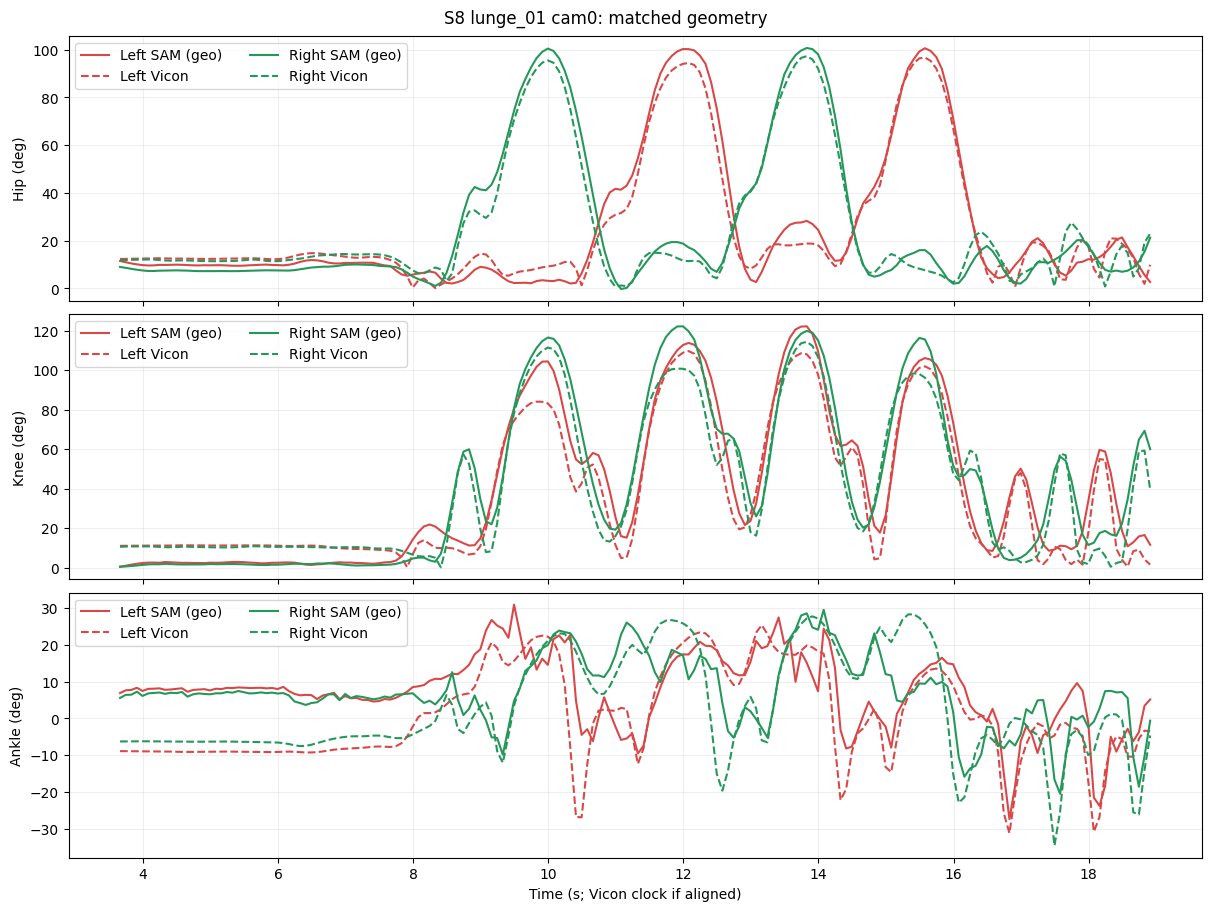

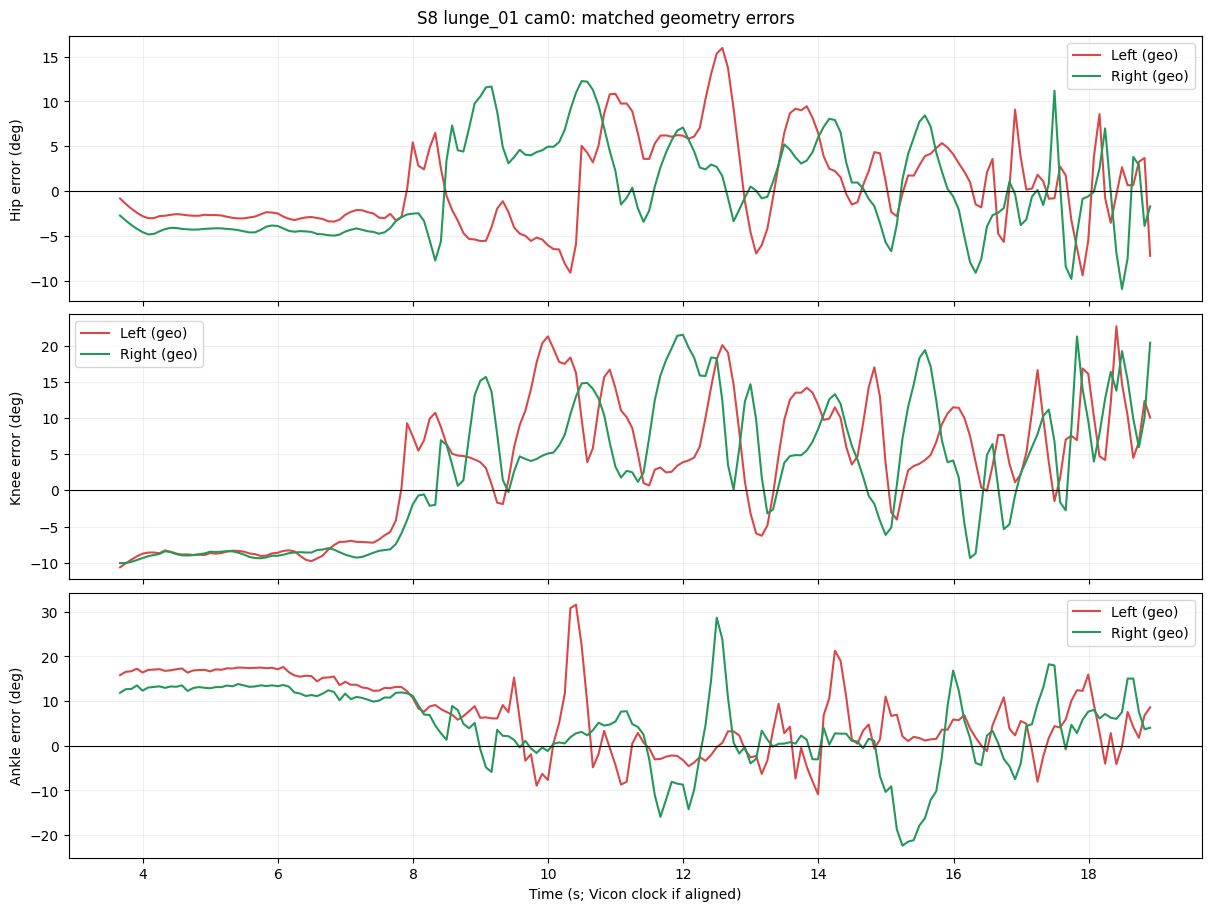

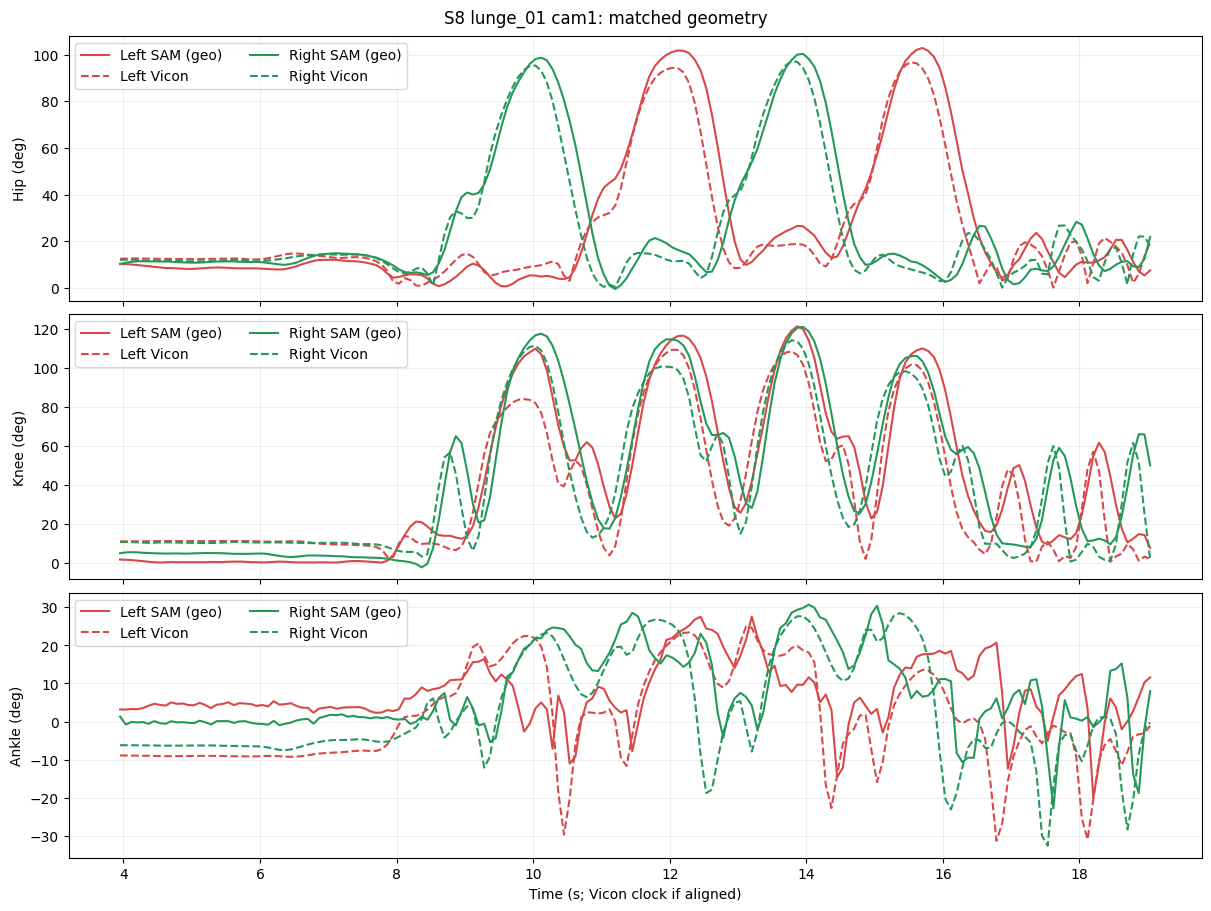

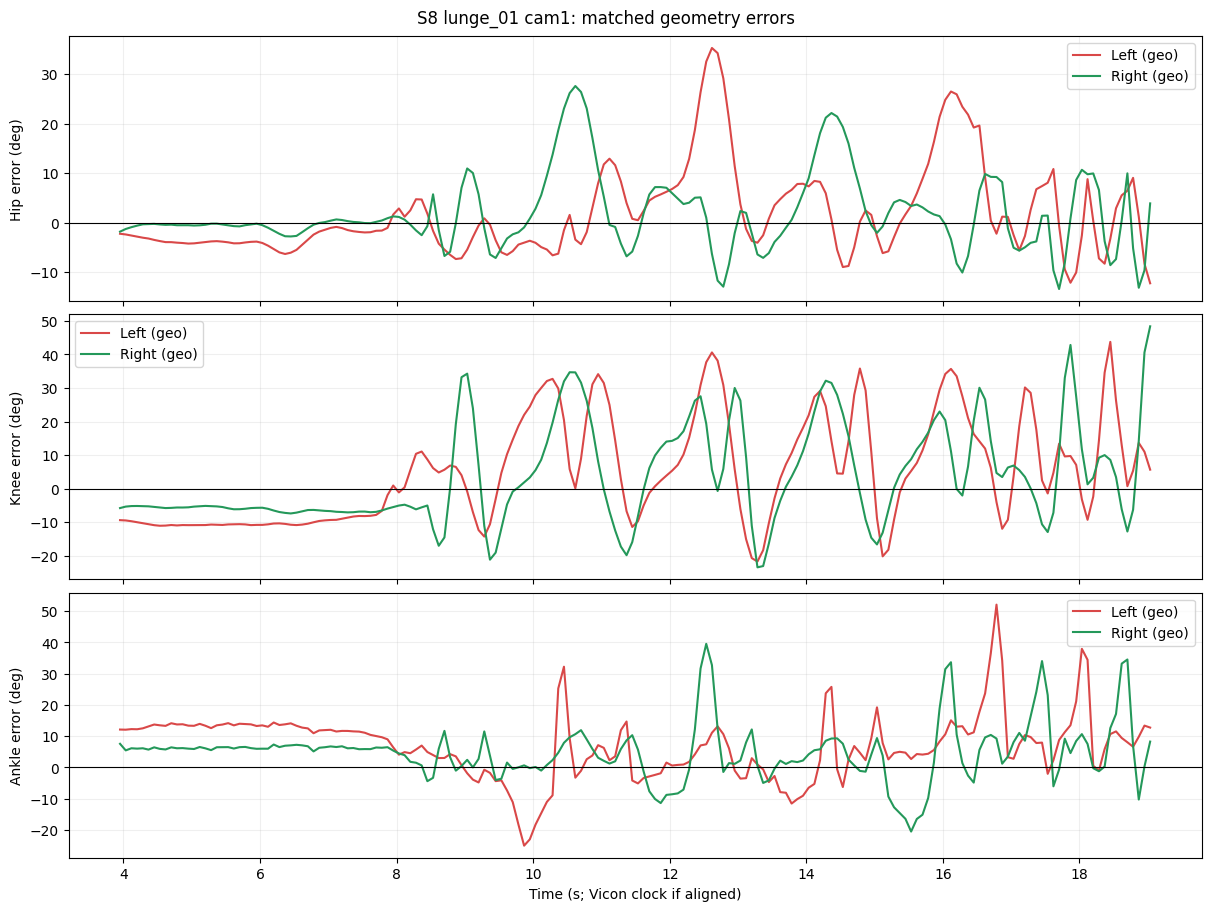

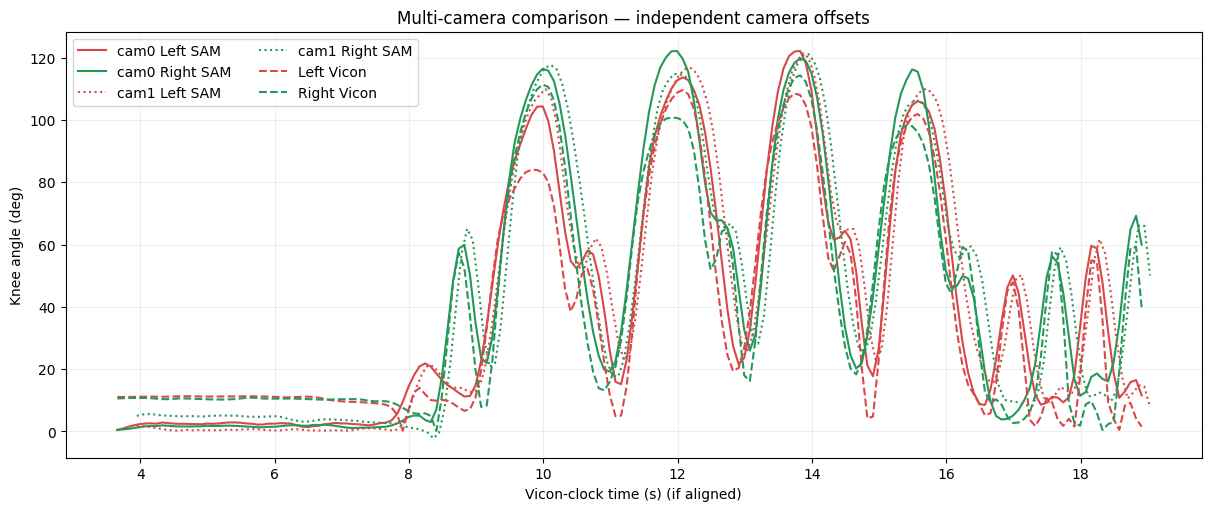

In [63]:
for camera, frame in aligned_by_camera.items():

    fig = plot_joint_overlays(
        frame,
        title=f"{SUBJECT} {TRIAL} {camera}: matched geometry",
        method="geo",
        vicon_reference="matched_geometry",
    )
    display(fig)
    plt.close(fig)

    fig = plot_joint_errors(
        frame,
        title=f"{SUBJECT} {TRIAL} {camera}: matched geometry errors",
        method="geo",
        vicon_reference="matched_geometry",
    )
    display(fig)
    plt.close(fig)

if len(aligned_by_camera) >= 2:
    fig = plot_camera_comparison(
        aligned_by_camera,
        joint="knee",
        method="geo",
        vicon_reference="matched_geometry",
    )
    display(fig)
    plt.close(fig)

## Troubleshooting angle definitions

In [64]:

# Read the validation metrics CSV file
metrics = pd.read_csv(RESULTS / SUBJECT / TRIAL / "validation_metrics_bilateral.csv")
geo = metrics[metrics["method"] == "geo"].copy()

geo["rmse_after_demeaning_deg"] = np.sqrt(
    np.maximum(
        geo["rmse_raw_deg"]**2 - geo["bias_deg"]**2,
        0
    )
)

print(
    geo[
        [
            "camera", "side", "joint",
            "rmse_raw_deg", "bias_deg",
            "rmse_after_demeaning_deg",
            "pearson_r", "rom_error_deg"
        ]
    ].round(2).to_string(index=False)
)

camera  side joint  rmse_raw_deg  bias_deg  rmse_after_demeaning_deg  pearson_r  rom_error_deg
  cam0 right   hip          5.12      0.05                      5.12       0.99           4.35
  cam0 right  knee          9.71      2.65                      9.34       0.98           7.45
  cam0 right ankle         77.81     77.33                      8.68       0.78         -21.62
  cam0  left   hip          5.03      0.49                      5.01       0.99           1.96
  cam0  left  knee          9.53      3.39                      8.90       0.98          12.35
  cam0  left ankle         80.70     80.26                      8.41       0.75         -10.76
  cam1 right   hip          7.74      1.76                      7.54       0.96           3.78
  cam1 right  knee         15.22      3.79                     14.74       0.93           9.86
  cam1 right ankle         78.30     77.84                      8.45       0.79         -16.63
  cam1  left   hip          9.14      1.77        

In [65]:
from scipy.stats import linregress

def angle_relationship(sam, vicon):
    sam = np.asarray(sam, dtype=float)
    vicon = np.asarray(vicon, dtype=float)

    valid = np.isfinite(sam) & np.isfinite(vicon)
    x = sam[valid]
    y = vicon[valid]

    if len(x) < 3 or np.std(x) < 1e-8:
        return None

    fit = linregress(x, y)

    return {
        "slope": fit.slope,
        "intercept_deg": fit.intercept,
        "r": fit.rvalue,
        "r2": fit.rvalue**2,
    }



In [66]:
for camera in CAMERAS:
    for side in SIDES:
        path = (
            TRIAL_RESULTS / camera / "validation"
            / side / "aligned_angles.csv"
        )

        if path.exists():
            df = pd.read_csv(path)

            print(f"\n{camera} / {side}")
            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())
            print(df.head(2).to_string(index=False))

In [67]:
for camera in CAMERAS:
    files = sorted(
        TRIAL_DATA.glob(f"*{camera}*sam_raw.npz")
    )

    print(camera, [f.name for f in files])

cam0 ['s8_lunge_cam0_sam_raw.npz']
cam1 ['s8_lunge_cam1_sam_raw.npz']


In [68]:
rows = []

for camera in CAMERAS:
    for side in SIDES:
        prefix = "r" if side == "right" else "l"

        path = (
            TRIAL_RESULTS
            / camera
            / "validation"
            / side
            / "aligned_angles.csv"
        )

        if not path.exists():
            print(f"Missing file: {path}")
            continue

        df = pd.read_csv(path)

        for joint in ("hip", "knee", "ankle"):

            sam_col = f"{prefix}_{joint}_flex_{METHOD}"
            vicon_col = f"{prefix}_vicon_{joint}_flex"

            if sam_col not in df.columns or vicon_col not in df.columns:
                print(f"Missing: {camera}/{side}/{joint}")
                continue

            result = angle_relationship(
                sam=df[sam_col],
                vicon=df[vicon_col]
            )

            if result is not None:
                rows.append({
                    "camera": camera,
                    "side": side,
                    "joint": joint,
                    "method": METHOD,
                    "n_valid": (
                        df[[sam_col, vicon_col]]
                        .dropna()
                        .shape[0]
                    ),
                    **result
                })

relationship_df = pd.DataFrame(rows)

display(relationship_df.round(3))

Missing file: /Users/thomasjohnson/markerless/markerless_sam/results/S8/lunge_01/cam0/validation/right/aligned_angles.csv
Missing file: /Users/thomasjohnson/markerless/markerless_sam/results/S8/lunge_01/cam0/validation/left/aligned_angles.csv
Missing file: /Users/thomasjohnson/markerless/markerless_sam/results/S8/lunge_01/cam1/validation/right/aligned_angles.csv
Missing file: /Users/thomasjohnson/markerless/markerless_sam/results/S8/lunge_01/cam1/validation/left/aligned_angles.csv


""


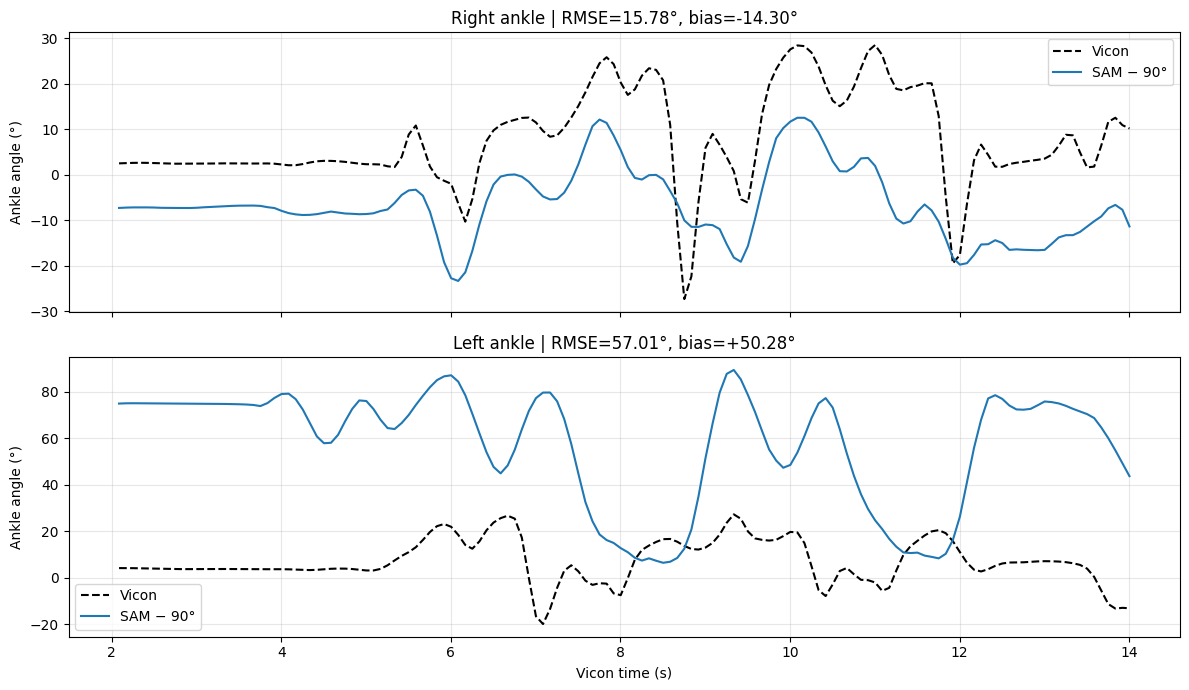

In [ ]:

# Diagnostic: RMSE and bias for both sides of a single camera
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for ax, side in zip(axes, ("right", "left")):
    p = "r" if side == "right" else "l"

    path = (
        TRIAL_RESULTS / "cam0" / "validation"
        / side / "aligned_angles.csv"
    )
    df = pd.read_csv(path)

    sam_col = f"{p}_ankle_flex_geo"
    vicon_col = f"{p}_vicon_ankle_flex"

    valid = (
        np.isfinite(df[sam_col])
        & np.isfinite(df[vicon_col])
        & np.isfinite(df["time_ms_aligned"])
    )
    d = df.loc[valid]

    t = d["time_ms_aligned"].to_numpy() / 1000
    sam = d[sam_col].to_numpy()
    vicon = d[vicon_col].to_numpy()

    corrected = sam - 90.0

    rmse = np.sqrt(np.mean((corrected - vicon)**2))
    bias = np.mean(corrected - vicon)

    ax.plot(t, vicon, "k--", label="Vicon")
    ax.plot(t, corrected, label="SAM − 90°")

    ax.set_title(
        f"{side.capitalize()} ankle | "
        f"RMSE={rmse:.2f}°, bias={bias:+.2f}°"
    )
    ax.set_ylabel("Ankle angle (°)")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Vicon time (s)")
plt.tight_layout()
plt.show()

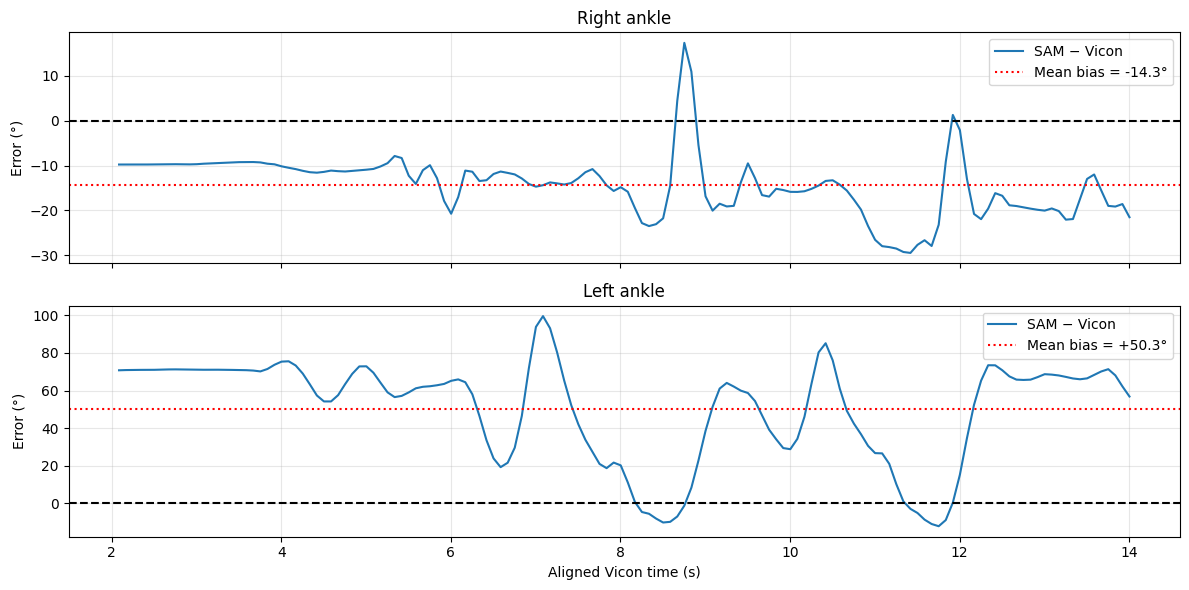

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

for ax, side in zip(axes, ("right", "left")):
    p = "r" if side == "right" else "l"

    df = pd.read_csv(
        TRIAL_RESULTS / "cam0" / "validation"
        / side / "aligned_angles.csv"
    )

    sam_col = f"{p}_ankle_flex_geo"
    vicon_col = f"{p}_vicon_ankle_flex"

    valid = df[[sam_col, vicon_col, "time_ms_aligned"]].notna().all(axis=1)
    d = df.loc[valid]
    t = d["time_ms_aligned"].to_numpy() / 1000
    sam = d[sam_col].to_numpy() - 90
    vicon = d[vicon_col].to_numpy()

    error = sam - vicon

    ax.plot(t, error, label="SAM − Vicon")
    ax.axhline(0, color="black", linestyle="--")
    ax.axhline(error.mean(), color="red", linestyle=":",
               label=f"Mean bias = {error.mean():+.1f}°")

    ax.set_ylabel("Error (°)")
    ax.set_title(f"{side.capitalize()} ankle")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Aligned Vicon time (s)")
plt.tight_layout()
plt.show()

In [ ]:
import importlib
import inspect
import src.vicon_parser as vp

importlib.reload(vp)

print("Parser path:", vp.__file__)
print(
    "Harrington implementation present:",
    "harrington_hjc" in inspect.getsource(vp.load_vicon_c3d)
)

vicon_df, vicon_rate, vicon_markers = vp.load_vicon_c3d(
    str(VICON_C3D)
)

print("\nAvailable hip columns:")
print([c for c in vicon_df.columns if "hip" in c])

Parser path: /Users/thomasjohnson/markerless/markerless_sam/src/vicon_parser.py
Harrington implementation present: True
Harrington HJC estimate:
  pelvis_width_mm: 238.40
  pelvis_depth_mm: 175.44
  hjc_ap_mm: -52.01
  hjc_si_mm: -82.42
  hjc_ml_mm: 85.97

Available hip columns:
['r_vicon_hip_flex', 'l_vicon_hip_flex', 'r_vicon_hip_flex_harrington', 'l_vicon_hip_flex_harrington', 'l_vicon_hip_unsigned_matched', 'l_vicon_hip_signed_matched', 'r_vicon_hip_unsigned_matched', 'r_vicon_hip_signed_matched']


In [ ]:
cols = [
    "r_vicon_hip_flex",
    "r_vicon_hip_flex_harrington",
    "l_vicon_hip_flex",
    "l_vicon_hip_flex_harrington",
]

static = vicon_df.loc[
    vicon_df["time_ms"].between(0, 500),
    cols
]

print("Initial Vicon angles:")
print(static.median().round(2).to_string())

Initial Vicon angles:
r_vicon_hip_flex              -16.67
r_vicon_hip_flex_harrington     0.80
l_vicon_hip_flex               -7.97
l_vicon_hip_flex_harrington     9.11


In [ ]:

from src.vicon_parser import build_pelvis_frame

# Use the markers returned by load_vicon_c3d()
m = vicon_markers  # Change to get_markers if that is your dictionary

_, pelvis_forward, pelvis_left, pelvis_up = build_pelvis_frame(
    m["LASI"], m["RASI"],
    m["LPSI"], m["RPSI"],
)

# Horizontal facing direction, independent of pelvic pitch
lab_forward = pelvis_forward.copy()
lab_forward[:, 2] = 0

lab_forward /= np.linalg.norm(
    lab_forward, axis=1, keepdims=True
)

lab_up = np.array([0.0, 0.0, 1.0])

# First 500 ms of Vicon recording
static_mask = vicon_df["time_ms"].between(0, 500).to_numpy()

rows = []

for side, hjc, kjc in [
    ("Right", m["RHJC_est"], m["RKJC_est"]),
    ("Left", m["LHJC_est"], m["LKJC_est"]),
]:

    thigh_down = kjc - hjc

    thigh_down = thigh_down / np.linalg.norm(
        thigh_down, axis=1, keepdims=True
    )

    # Thigh orientation relative to laboratory vertical
    global_angle = np.degrees(np.arctan2(
        np.sum(thigh_down * lab_forward, axis=1),
        -(thigh_down @ lab_up)
    ))

    # Thigh orientation relative to pelvic frame
    pelvis_angle = np.degrees(np.arctan2(
        np.sum(thigh_down * pelvis_forward, axis=1),
        -np.sum(thigh_down * pelvis_up, axis=1)
    ))

    rows.append({
        "side": side,
        "global_thigh_angle_deg": np.nanmedian(
            global_angle[static_mask]
        ),
        "pelvis_relative_hip_deg": np.nanmedian(
            pelvis_angle[static_mask]
        ),
    })

display(pd.DataFrame(rows).round(2))


asis_mid = (m["LASI"] + m["RASI"]) / 2
psis_mid = (m["LPSI"] + m["RPSI"]) / 2

static_mask = vicon_df["time_ms"].between(0, 500).to_numpy()

# Positive if PSIS is superior to ASIS
height_difference = psis_mid[:, 2] - asis_mid[:, 2]

pelvic_tilt = np.degrees(np.arctan2(
    height_difference,
    np.linalg.norm(
        (asis_mid - psis_mid)[:, :2],
        axis=1
    )
))

print(
    "Median ASIS–PSIS height difference (mm):",
    np.nanmedian(height_difference[static_mask]).round(2)
)

print(
    "Median pelvic inclination (deg):",
    np.nanmedian(pelvic_tilt[static_mask]).round(2)
)

,side,global_thigh_angle_deg,pelvis_relative_hip_deg
0,Right,-4.32,0.80
1,Left,3.95,9.11


Median ASIS–PSIS height difference (mm): 15.41
Median pelvic inclination (deg): 5.13


In [ ]:
matched_cols = [
    col for col in vicon_df.columns
    if col.endswith("_matched")
]

assert len(matched_cols) == 8, (
    f"Expected 8 matched columns, got {len(matched_cols)}"
)

display(vicon_df[["time_ms", *matched_cols]].head())

,time_ms,l_vicon_hip_unsigned_matched,l_vicon_hip_signed_matched,l_vicon_knee_flex_matched,l_vicon_ankle_df_matched,r_vicon_hip_unsigned_matched,r_vicon_hip_signed_matched,r_vicon_knee_flex_matched,r_vicon_ankle_df_matched
0,0.0,5.064642,5.064642,10.494336,4.752388,0.480211,-0.480211,2.354757,2.038222
1,10.0,5.218993,5.218993,10.626752,4.691003,0.460535,-0.460535,2.328118,2.003655
2,20.0,5.373733,5.373733,10.770128,4.639063,0.443552,-0.443552,2.301008,1.970738
3,30.0,5.528820,5.528820,10.924377,4.596539,0.429247,-0.429247,2.273440,1.939463
4,40.0,5.684282,5.684282,11.089531,4.563478,0.417626,-0.417626,2.245386,1.909802


In [ ]:
static = vicon_df["time_ms"].between(0, 500)

display(
    vicon_df.loc[static, matched_cols]
    .median()
    .round(2)
    .to_frame("Initial angle (°)")
)

,Initial angle (°)
l_vicon_hip_unsigned_matched,7.37
l_vicon_hip_signed_matched,7.37
l_vicon_knee_flex_matched,15.25
l_vicon_ankle_df_matched,5.78
r_vicon_hip_unsigned_matched,0.83
r_vicon_hip_signed_matched,-0.83
r_vicon_knee_flex_matched,1.53
r_vicon_ankle_df_matched,1.53


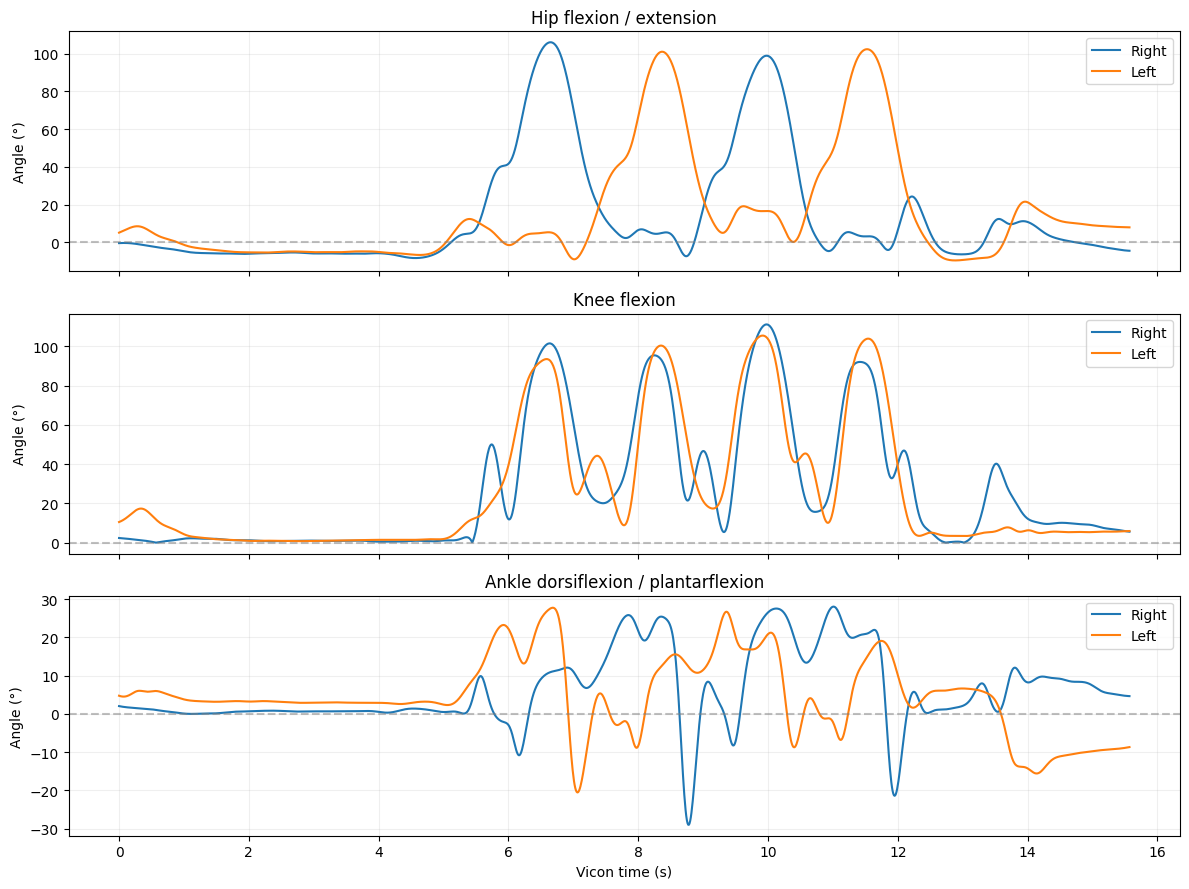

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

metrics = [
    ("hip_signed", "Hip flexion / extension"),
    ("knee_flex", "Knee flexion"),
    ("ankle_df", "Ankle dorsiflexion / plantarflexion"),
]

t = vicon_df["time_ms"] / 1000

for ax, (metric, title) in zip(axes, metrics):
    for side, label in (("r", "Right"), ("l", "Left")):
        ax.plot(
            t,
            vicon_df[f"{side}_vicon_{metric}_matched"],
            label=label,
        )

    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
    ax.set_ylabel("Angle (°)")
    ax.set_title(title)
    ax.grid(alpha=0.2)
    ax.legend()

axes[-1].set_xlabel("Vicon time (s)")
plt.tight_layout()
plt.show()

,side,shank_orientation_deg,foot_orientation_deg,ankle_df_matched_deg
0,L,82.13,-2.08,5.78
1,R,87.50,-0.83,1.53


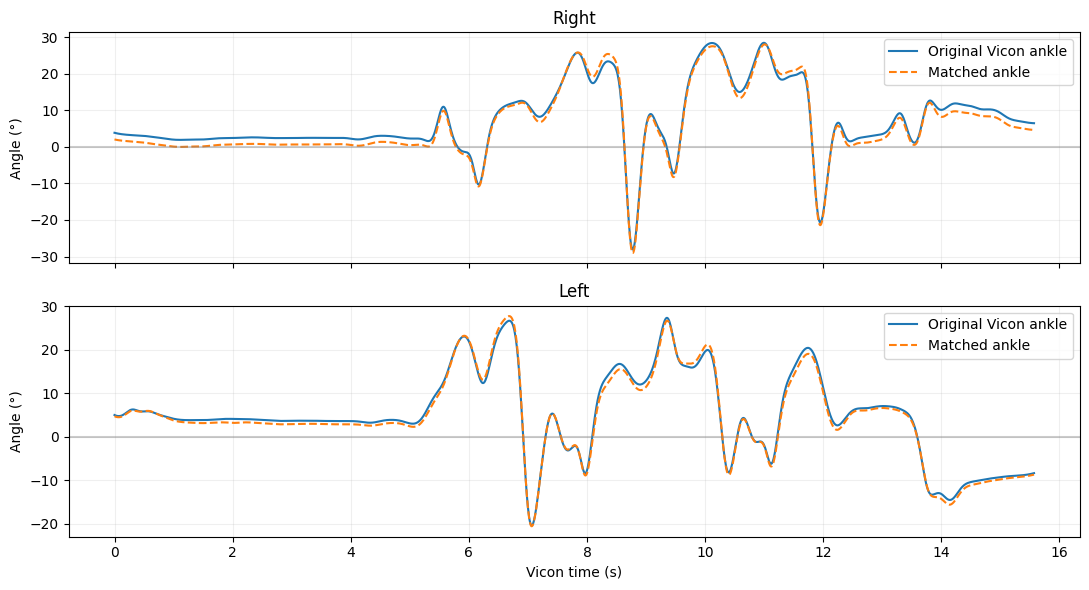

In [ ]:
from src.joint_angle_geometry import unit

m = vicon_markers

LHJC = m["LHJC_est"]
RHJC = m["RHJC_est"]

mid_hip = (LHJC + RHJC) / 2

# Use the same shoulder selection as vicon_parser.py
# These are examples; use your parser's fallback logic
l_sh = m["LCLAVLAT"]
r_sh = m["RCLAVLAT"]
mid_sh = (l_sh + r_sh) / 2

left = unit(LHJC - RHJC)
up_temp = unit(mid_sh - mid_hip)
forward = unit(np.cross(left, up_temp))
up = unit(np.cross(forward, left))

def project(v):
    return np.column_stack((
        np.sum(v * forward, axis=1),
        np.sum(v * up, axis=1),
    ))

static = vicon_df["time_ms"].between(0, 500).to_numpy()

rows = []

for side in ("L", "R"):
    ankle = m[f"{side}AJC_est"]
    knee = m[f"{side}KJC_est"]
    heel = m[f"{side}HEEL"]
    toe = m[f"{side}TOE"]

    shank = project(knee - ankle)
    foot = project(toe - heel)

    # Angles from projected forward axis
    shank_orientation = np.degrees(
        np.arctan2(shank[:, 1], shank[:, 0])
    )
    foot_orientation = np.degrees(
        np.arctan2(foot[:, 1], foot[:, 0])
    )

    rows.append({
        "side": side,
        "shank_orientation_deg":
            np.nanmedian(shank_orientation[static]),
        "foot_orientation_deg":
            np.nanmedian(foot_orientation[static]),
        "ankle_df_matched_deg":
            np.nanmedian(
                vicon_df.loc[
                    static,
                    f"{side.lower()}_vicon_ankle_df_matched"
                ]
            ),
    })

display(pd.DataFrame(rows).round(2))

# Diagnostic: compare original Vicon ankle flexion to matched angles
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

for ax, side, label in zip(
    axes, ("r", "l"), ("Right", "Left")
):
    t = vicon_df["time_ms"] / 1000

    ax.plot(
        t,
        vicon_df[f"{side}_vicon_ankle_flex"],
        label="Original Vicon ankle"
    )

    ax.plot(
        t,
        vicon_df[f"{side}_vicon_ankle_df_matched"],
        label="Matched ankle",
        linestyle="--"
    )

    ax.axhline(0, color="gray", alpha=0.4)
    ax.set_title(label)
    ax.set_ylabel("Angle (°)")
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Vicon time (s)")
plt.tight_layout()
plt.show()


In [ ]:
# Diagnostic: foot inclination relative to horizontal plane

static = vicon_df["time_ms"].between(0, 500).to_numpy()

rows = []

for side in ("L", "R"):
    foot = (
        vicon_markers[f"{side}TOE"]
        - vicon_markers[f"{side}HEEL"]
    )

    horizontal_length = np.linalg.norm(foot[:, :2], axis=1)

    foot_inclination = np.degrees(
        np.arctan2(foot[:, 2], horizontal_length)
    )

    rows.append({
        "side": side,
        "foot_inclination_lab_deg": np.nanmedian(
            foot_inclination[static]
        ),
        "foot_orientation_sagittal_deg": (
            -9.60 if side == "L" else -12.51
        ),
    })

display(pd.DataFrame(rows).round(2))

,side,foot_inclination_lab_deg,foot_orientation_sagittal_deg
0,L,-5.58,-9.60
1,R,-4.64,-12.51


## Interpretation and limitations
- `sync_candidate.json` is still **review**, not accepted synchronization.
- The current SAM `joint_angles.csv` files may only contain genuine right-leg angles; missing left-side values must not be fabricated.
- If the angle CSV has original `time_ms`, it must match the corresponding `sam_sync.csv` `ts` row by row. Legacy files without original time recover it only after verifying a constant offset from `time_ms_aligned`. The engine rejects unequal row counts; do not truncate files or force row-wise matching.
- The user must verify that the historical angle export did not interpolate/resample the SAM values.
- C3D marker-based hip/ankle angles require anatomical and sign-convention QC before reporting clinical accuracy.
- `plotting.py` must be the updated bilateral version that accepts `method=`.
- No joint-derived timing adjustment or neutral calibration is applied in this notebook.
